# 12 - Underfitting Check (model 1 & model 2)

Underfitting (high bias) is the **opposite** of overfitting:
- **Overfitting** = high train score, low test score (big gap).
- **Underfitting** = **low train AND low test**, and the model barely beats a
  trivial baseline - it is too weak to even fit what it has seen.

So this notebook reports, for each model:
1. **train vs test** accuracy / macro-F1 (can it fit the training data?),
2. the **majority-class** and **random** baselines + the **margin** the model beats them by,
3. **per-class recall** (underfitting often leaves some classes near zero).

No retraining - it loads your saved `model23` models and evaluates. Reuses the
exact same split as notebooks 01 / 02 (SEED 42). Run top to bottom on Colab GPU.

In [1]:
import torch, os
assert torch.cuda.is_available(), 'No GPU active. Runtime > Change runtime type > GPU, then re-run.'
print('GPU:', torch.cuda.get_device_name(0))
from google.colab import drive
if not os.path.isdir('/content/drive/MyDrive'):
    drive.mount('/content/drive')
print('Drive ready:', os.path.isdir('/content/drive/MyDrive'))
!pip install -q opencv-python-headless seaborn gdown

GPU: Tesla T4
Drive ready: True


In [2]:
import os
CLASSES = [
    (0, 'Short Serve', '00_Short Serve'),
    (1, 'Lift',        '02_Lift'),
    (2, 'Clear',       '12_Clear'),
    (3, 'Drop Shot',   '05_Drop Shot'),
    (4, 'Smash',       '14_Smash'),
]
NUM_CLASSES   = len(CLASSES)
DISPLAY_NAMES = [c[1] for c in CLASSES]
CLASS_FOLDERS = [c[2] for c in CLASSES]
FOLDER_TO_ID  = {c[2]: c[0] for c in CLASSES}
ID_TO_NAME    = {c[0]: c[1] for c in CLASSES}
PAD_TOKEN     = NUM_CLASSES
SEED          = 42

DRIVE       = '/content/drive/MyDrive/BadmintonFYP'
MODELS      = DRIVE + '/model23'
VIDEO_CKPT  = MODELS + '/video_model.pth'
SEQ_CKPT    = MODELS + '/sequence_model.pth'
DATASET_ZIP = DRIVE + '/DATASET2.zip'

NUM_FRAMES = 16; IMG = 224; BATCH = 8
IMAGENET_MEAN = [0.485, 0.456, 0.406]; IMAGENET_STD = [0.229, 0.224, 0.225]
SEQ_LEN = 4
SHUTTLESET_DIR = '/content/ShuttleSet22'
SHUTTLE_MAP = {
    '發短球': 0, '發長球': 0,
    '挑球': 1, '防守回挑': 1,
    '長球': 2, '平球': 2, '小平球': 2, '後場抽平球': 2, '防守回抽': 2,
    '切球': 3, '過度切球': 3, '過渡切球': 3, '放小球': 3, '擋小球': 3, '勾球': 3, '推球': 3,
    '殺球': 4, '點扣': 4, '撲球': 4,
}

from collections import Counter
def baselines(train_labels, test_labels, num_classes):
    maj = Counter(train_labels).most_common(1)[0][0]
    maj_acc = sum(1 for y in test_labels if y == maj) / len(test_labels)
    return maj, maj_acc, 1.0 / num_classes

def verdict(tr_acc, te_acc, maj_acc, name):
    margin = te_acc - maj_acc
    print()
    print('UNDERFITTING VERDICT (' + name + ')')
    if tr_acc < 0.70:
        print('=> UNDERFITTING (high bias): cannot fit training data well (train acc %.2f).' % tr_acc)
        print('   Fix: more capacity / train longer / richer features.')
    elif margin < 0.05:
        print('=> WEAK: test only %.1f pts above majority guessing (%.2f vs %.2f) - borderline underfitting.' % (100*margin, te_acc, maj_acc))
    else:
        print('=> NOT underfitting: fits training (train acc %.2f) and beats majority by %.1f pts (%.2f vs %.2f).' % (tr_acc, 100*margin, te_acc, maj_acc))
    return margin

print('config + helpers ready | video ckpt exists:', os.path.exists(VIDEO_CKPT))

config + helpers ready | video ckpt exists: True


## Part A - Video stroke classifier (model 1)

In [3]:
import glob, zipfile, shutil
import numpy as np, pandas as pd, cv2
import torch.nn as nn
import torchvision.models as models
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import accuracy_score, f1_score, classification_report

np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

EXTRACT_DIR = '/content/data'; GDRIVE_FILE_ID = ''
def has_all(d): return os.path.isdir(d) and all(os.path.isdir(os.path.join(d, f)) for f in CLASS_FOLDERS)
def find_root(base):
    for c in [base] + sorted(glob.glob(base + '/*')) + sorted(glob.glob(base + '/*/*')):
        if os.path.isdir(c) and any(os.path.isdir(os.path.join(c, f)) for f in CLASS_FOLDERS): return c
    return None
root = find_root(EXTRACT_DIR)
if root is None or not has_all(root):
    zips = []
    for pat in (DATASET_ZIP, DRIVE + '/*.zip', '/content/drive/MyDrive/*.zip', '/content/*.zip'):
        zips += glob.glob(pat)
    zips = sorted(set(z for z in zips if os.path.exists(z)), key=lambda z: (0 if 'dataset' in z.lower() else 1, len(z)))
    if not zips:
        try:
            import gdown; out = '/content/DATASET2.zip'
            if not os.path.exists(out):
                print('Downloading DATASET2.zip...'); gdown.download(id=GDRIVE_FILE_ID, output=out, quiet=False)
            if os.path.exists(out) and os.path.getsize(out) > 1000000: zips = [out]
        except Exception as e: print('gdown failed:', e)
    if zips:
        print('Extracting', zips[0])
        if os.path.exists(EXTRACT_DIR): shutil.rmtree(EXTRACT_DIR)
        with zipfile.ZipFile(zips[0]) as z: z.extractall(EXTRACT_DIR)
        root = find_root(EXTRACT_DIR)
DATASET_DIR = root or EXTRACT_DIR
print('Using DATASET_DIR =', DATASET_DIR)

def load_video_frames(path, num_frames=NUM_FRAMES):
    cap = cv2.VideoCapture(path)
    if not cap.isOpened(): raise ValueError('cannot open ' + path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total == 0: cap.release(); raise ValueError('0 frames ' + path)
    idxs = np.linspace(0, total - 1, num_frames, dtype=int); frames = []
    for i in idxs:
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(i)); ok, fr = cap.read()
        if ok: frames.append(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
        elif frames: frames.append(frames[-1].copy())
    cap.release()
    while len(frames) < num_frames: frames.append(frames[-1].copy() if frames else np.zeros((IMG, IMG, 3), np.uint8))
    return frames[:num_frames]
def letterbox(img, size=IMG):
    h, w = img.shape[:2]; s = min(size / h, size / w); nh, nw = int(h * s), int(w * s)
    r = cv2.resize(img, (nw, nh)); canvas = np.zeros((size, size, 3), np.uint8)
    y, x = (size - nh) // 2, (size - nw) // 2; canvas[y:y+nh, x:x+nw] = r; return canvas
_norm = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
def preprocess_frames(frames, size=IMG):
    out = []
    for fr in frames:
        fr = letterbox(fr, size).astype(np.float32) / 255.0
        out.append(_norm(torch.from_numpy(fr).permute(2, 0, 1)))
    return torch.stack(out)
class VideoClipDataset(Dataset):
    def __init__(self, df): self.df = df.reset_index(drop=True)
    def __len__(self): return len(self.df)
    def __getitem__(self, i):
        row = self.df.iloc[i]
        try: return preprocess_frames(load_video_frames(row.file_path)), int(row.label_id)
        except Exception as e: print('skip', row.file_path, e); return torch.zeros(NUM_FRAMES, 3, IMG, IMG), int(row.label_id)
def build_index(root):
    rows = []
    for folder in CLASS_FOLDERS:
        p = os.path.join(root, folder)
        if not os.path.isdir(p): print('missing folder', p); continue
        lid = FOLDER_TO_ID[folder]
        for fn in os.listdir(p):
            if fn.lower().endswith('.mp4'):
                gid = fn.split('_dataset_set')[0] if '_dataset_set' in fn else fn[:19]
                rows.append({'file_path': os.path.join(p, fn), 'label_id': lid, 'label_name': folder, 'group_id': gid})
    return pd.DataFrame(rows)
def group_split(df, val=0.15, test=0.15, seed=SEED):
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(df, groups=df.group_id))
    dtr, dtmp = df.iloc[tr].reset_index(drop=True), df.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.group_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
class TemporalPoolingResNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        base = models.resnet18(weights=None)
        self.features = nn.Sequential(*list(base.children())[:-1])
        self.fc = nn.Linear(512, num_classes)
    def forward(self, x):
        b, t, c, h, w = x.shape
        x = x.view(b * t, c, h, w)
        x = self.features(x).view(b, t, 512).mean(dim=1)
        return self.fc(x)
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); P, L = [], []
    for x, y in loader:
        out = model(x.to(DEVICE)); P += out.argmax(1).cpu().tolist(); L += y.tolist()
    return accuracy_score(L, P), f1_score(L, P, average='macro'), P, L
print('video defs ready')

Using DATASET_DIR = /content/data
video defs ready


loaded /content/drive/MyDrive/BadmintonFYP/model23/video_model.pth
skip /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4 cannot open /content/data/00_Short Serve/2022-08-31_18-50-39_dataset_set1_004_001116_001116_A_00.mp4

                accuracy   macro-F1
train            0.988      0.989
test             0.951      0.947
majority "Clear"   0.178       -    (always predict the most common class)
random            0.200       -    (1 / 5 classes)

Per-class recall (a near-zero row = a class the model failed to learn):
              precision    recall  f1-score   support

 Short Serve       1.00      0.99      0.99       190
        Lift       0.98      0.87      0.92       152
       Clear       0.85      0.98      0.91       130
   Drop Shot       0.97      0.96      0.97       155
       Smash       0.94      0.95      0.95       105

    accuracy                           0.95       732
   macro avg       0.95      0.95      0.95       732


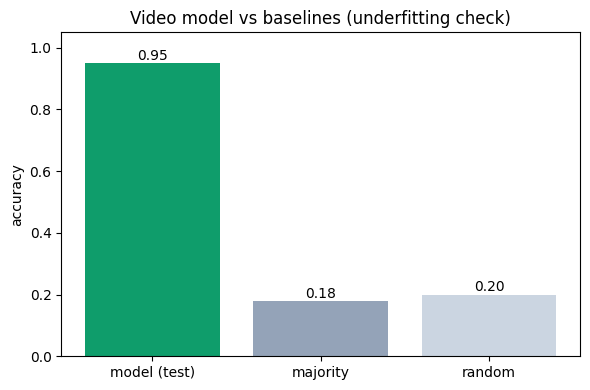

Saved chart to /content/drive/MyDrive/BadmintonFYP/model23/underfitting_video.png


In [4]:
import matplotlib.pyplot as plt

df = build_index(DATASET_DIR); df_train, df_val, df_test = group_split(df)
model = TemporalPoolingResNet().to(DEVICE)
assert os.path.exists(VIDEO_CKPT), 'missing ' + VIDEO_CKPT
model.load_state_dict(torch.load(VIDEO_CKPT, map_location=DEVICE)); print('loaded', VIDEO_CKPT)

tr_acc, tr_f1, _, trL    = evaluate(model, DataLoader(VideoClipDataset(df_train), batch_size=BATCH, num_workers=2))
te_acc, te_f1, teP, teL  = evaluate(model, DataLoader(VideoClipDataset(df_test),  batch_size=BATCH, num_workers=2))
maj, maj_acc, rand_acc = baselines(df_train.label_id.tolist(), teL, NUM_CLASSES)

print()
print('                accuracy   macro-F1')
print('train            %.3f      %.3f' % (tr_acc, tr_f1))
print('test             %.3f      %.3f' % (te_acc, te_f1))
print('majority "%s"   %.3f       -    (always predict the most common class)' % (ID_TO_NAME[maj], maj_acc))
print('random            %.3f       -    (1 / %d classes)' % (rand_acc, NUM_CLASSES))
print()
print('Per-class recall (a near-zero row = a class the model failed to learn):')
print(classification_report(teL, teP, labels=list(range(NUM_CLASSES)), target_names=DISPLAY_NAMES, digits=2))
margin = verdict(tr_acc, te_acc, maj_acc, 'video classifier')

plt.figure(figsize=(6, 4))
bars = ['model (test)', 'majority', 'random']; vals = [te_acc, maj_acc, rand_acc]
plt.bar(bars, vals, color=['#0f9d6b', '#94a3b8', '#cbd5e1'])
for i, v in enumerate(vals): plt.text(i, v + 0.01, '%.2f' % v, ha='center', fontsize=10)
plt.ylim(0, 1.05); plt.ylabel('accuracy'); plt.title('Video model vs baselines (underfitting check)')
plt.tight_layout(); plt.savefig(MODELS + '/underfitting_video.png', dpi=150); plt.show()
print('Saved chart to', MODELS + '/underfitting_video.png')

## Part B - Next-shot GRU (model 2)

The GRU's top-1 looks modest **by nature** - predicting a human's next shot is
stochastic. The test below shows it still **beats the majority baseline** and that
**top-3** is high, i.e. it is near the task ceiling, not underfitting.

In [5]:
import urllib.request

SET_FOLDER = SHUTTLESET_DIR + '/set'
if not (os.path.isdir(SET_FOLDER) and os.listdir(SET_FOLDER)):
    url = 'https://github.com/wywyWang/CoachAI-Projects/archive/refs/heads/main.zip'; zp = '/content/coachai.zip'
    print('Downloading ShuttleSet22 ...'); urllib.request.urlretrieve(url, zp)
    with zipfile.ZipFile(zp) as z: z.extractall('/content/_ca')
    src = '/content/_ca/CoachAI-Projects-main/CoachAI-Challenge-IJCAI2023/ShuttleSet22'
    if os.path.exists(SHUTTLESET_DIR): shutil.rmtree(SHUTTLESET_DIR)
    shutil.move(src, SHUTTLESET_DIR)
print('set folder present:', os.path.isdir(SET_FOLDER))

def parse_rallies(set_folder):
    rallies, skipped = [], []
    for match in os.listdir(set_folder):
        mp = os.path.join(set_folder, match)
        if not os.path.isdir(mp): continue
        for sf in ('set1.csv', 'set2.csv', 'set3.csv'):
            path = os.path.join(mp, sf)
            if not os.path.exists(path): continue
            try: d = pd.read_csv(path)
            except Exception as e: print('read err', e); continue
            if 'rally' not in d.columns or 'type' not in d.columns: continue
            for rid, rd in d.groupby('rally'):
                shots = []
                for t in rd['type'].astype(str).str.strip():
                    if t in SHUTTLE_MAP: shots.append(SHUTTLE_MAP[t])
                    else: skipped.append(t)
                if len(shots) >= 2: rallies.append({'match_id': match, 'shots': shots})
    return rallies
def build_windows(rallies, seq_len=SEQ_LEN):
    w = []
    for r in rallies:
        s = r['shots']
        for i in range(len(s)):
            hist = s[max(0, i - seq_len):i]
            if len(hist) < seq_len: hist = [PAD_TOKEN] * (seq_len - len(hist)) + hist
            w.append({'input': hist, 'target': s[i], 'match_id': r['match_id']})
    return w
def seq_group_split(windows, val=0.15, test=0.15, seed=SEED):
    d = pd.DataFrame(windows)
    g1 = GroupShuffleSplit(n_splits=1, test_size=val + test, random_state=seed)
    tr, tmp = next(g1.split(d, groups=d.match_id))
    dtr, dtmp = d.iloc[tr].reset_index(drop=True), d.iloc[tmp].reset_index(drop=True)
    g2 = GroupShuffleSplit(n_splits=1, test_size=test / (val + test), random_state=seed)
    va, te = next(g2.split(dtmp, groups=dtmp.match_id))
    return dtr, dtmp.iloc[va].reset_index(drop=True), dtmp.iloc[te].reset_index(drop=True)
class SequenceDataset(Dataset):
    def __init__(self, df):
        self.x = [torch.tensor(a, dtype=torch.long) for a in df['input']]
        self.y = torch.tensor(df['target'].values, dtype=torch.long)
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.x[i], self.y[i]
class ShotPredictorGRU(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, embed=32, hidden=128, layers=2, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(num_classes + 1, embed, padding_idx=PAD_TOKEN)
        self.gru = nn.GRU(embed, hidden, layers, batch_first=True, dropout=drop if layers > 1 else 0)
        self.fc = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(drop), nn.Linear(hidden, num_classes))
    def forward(self, x):
        x = self.emb(x); o, _ = self.gru(x); return self.fc(o[:, -1, :])
@torch.no_grad()
def evaluate_seq(m, loader):
    m.eval(); P, L, t3, n = [], [], 0.0, 0
    for x, y in loader:
        lg = m(x.to(DEVICE)).cpu()
        P += lg.argmax(1).tolist(); L += y.tolist()
        t3 += (lg.topk(3, 1).indices == y.unsqueeze(1)).any(1).float().sum().item(); n += len(y)
    return accuracy_score(L, P), f1_score(L, P, average='macro'), t3 / n, P, L

rallies = parse_rallies(SET_FOLDER); windows = build_windows(rallies)
sdf_train, sdf_val, sdf_test = seq_group_split(windows)
print('windows', len(windows), '| train', len(sdf_train), 'test', len(sdf_test))

set folder present: True
windows 51173 | train 34558 test 8563


loaded /content/drive/MyDrive/BadmintonFYP/model23/sequence_model.pth

                  accuracy   macro-F1   top-3
train              0.528      0.554     0.971
test               0.535      0.567     0.971
majority "Drop Shot"   0.439        -         -   (always predict the most common class)
random              0.200        -         -   (1 / 5 classes)

Per-class recall:
              precision    recall  f1-score   support

 Short Serve       0.87      1.00      0.93       681
        Lift       0.45      0.67      0.54      1716
       Clear       0.41      0.34      0.37      1253
   Drop Shot       0.69      0.44      0.53      3763
       Smash       0.38      0.59      0.46      1150

    accuracy                           0.53      8563
   macro avg       0.56      0.61      0.57      8563
weighted avg       0.57      0.53      0.53      8563


UNDERFITTING VERDICT (next-shot GRU)
=> UNDERFITTING (high bias): cannot fit training data well (train acc 0.53).
   Fix: more cap

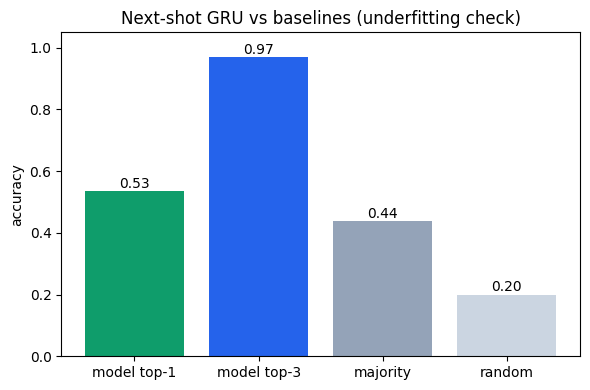

Saved chart to /content/drive/MyDrive/BadmintonFYP/model23/underfitting_sequence.png


In [6]:
smodel = ShotPredictorGRU().to(DEVICE)
assert os.path.exists(SEQ_CKPT), 'missing ' + SEQ_CKPT
smodel.load_state_dict(torch.load(SEQ_CKPT, map_location=DEVICE)); print('loaded', SEQ_CKPT)

tr_acc, tr_f1, tr_t3, _, trL   = evaluate_seq(smodel, DataLoader(SequenceDataset(sdf_train), batch_size=64))
te_acc, te_f1, te_t3, teP, teL = evaluate_seq(smodel, DataLoader(SequenceDataset(sdf_test),  batch_size=64))
maj, maj_acc, rand_acc = baselines(sdf_train.target.tolist(), teL, NUM_CLASSES)

print()
print('                  accuracy   macro-F1   top-3')
print('train              %.3f      %.3f     %.3f' % (tr_acc, tr_f1, tr_t3))
print('test               %.3f      %.3f     %.3f' % (te_acc, te_f1, te_t3))
print('majority "%s"   %.3f        -         -   (always predict the most common class)' % (ID_TO_NAME[maj], maj_acc))
print('random              %.3f        -         -   (1 / %d classes)' % (rand_acc, NUM_CLASSES))
print()
print('Per-class recall:')
print(classification_report(teL, teP, labels=list(range(NUM_CLASSES)), target_names=DISPLAY_NAMES, digits=2))
margin = verdict(tr_acc, te_acc, maj_acc, 'next-shot GRU')
print('Note: next-shot is stochastic (predicting a human choice). Top-1 beats the')
print('%.0f%% majority baseline and top-3 = %.0f%%, so the model is near the task' % (100*maj_acc, 100*te_t3))
print('ceiling - low top-1 here is irreducible uncertainty, not high-bias underfitting.')

import matplotlib.pyplot as plt
plt.figure(figsize=(6, 4))
bars = ['model top-1', 'model top-3', 'majority', 'random']; vals = [te_acc, te_t3, maj_acc, rand_acc]
plt.bar(bars, vals, color=['#0f9d6b', '#2563eb', '#94a3b8', '#cbd5e1'])
for i, v in enumerate(vals): plt.text(i, v + 0.01, '%.2f' % v, ha='center', fontsize=10)
plt.ylim(0, 1.05); plt.ylabel('accuracy'); plt.title('Next-shot GRU vs baselines (underfitting check)')
plt.tight_layout(); plt.savefig(MODELS + '/underfitting_sequence.png', dpi=150); plt.show()
print('Saved chart to', MODELS + '/underfitting_sequence.png')